# 건물 속성 빈칸 추정: 지상층수 (Keras Dense)

사창동 건물 2,448동 중 건축물대장 속성(용도·연면적·지상층수·사용승인일)이 비어 있는 건물이 있다. 이 건물들은 지도에서 늘 **판정불가**로 남는다.
모든 건물에 있는 정보(바닥 모양, 위치, 주변 건물)만으로 **지상층수 구간**을 추정하는 신경망을 만든다.

추정값은 화면에서 **참고용**으로만 보여 주고, 법안 판정에는 쓰지 않는다 (판정은 건축물대장 실제 값만 사용).

**순서**: 1 문제 → 2 데이터 → 3 전처리 (특징 만들기) → 4 학습/테스트 분리 → 5 기준선 → 6 신경망 → 7 과적합 확인 → 8 은닉층 실험 → 9 오답 분석 → 10 결과표 → 11 화면에 쓰이는 곳

## 0. 준비 (Colab 한글 글꼴 설치)

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('/usr/share/fonts/truetype/nanum'):
    !apt-get -qq install fonts-nanum > /dev/null

In [2]:
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import json, base64, urllib.request, urllib.parse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import matplotlib.font_manager as fm
_f = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if os.path.exists(_f):
    fm.fontManager.addfont(_f)                       # 세션 다시 시작 없이 한글 글꼴 등록
    plt.rcParams['font.family'] = fm.FontProperties(fname=_f).get_name()
plt.rcParams['axes.unicode_minus'] = False

SEED = 42
np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()   # 다시 실행해도 같은 결과

## 1. 문제
- **입력**: 건물마다 반드시 있는 것만 쓴다. 바닥 도형(면적·둘레·모양), 위치, 그리고 **속성이 있는 주변 건물**의 층수·사용승인 연도.
- **출력**: 지상층수 구간 5개 중 하나 (softmax 확률).
- **학습 데이터**: 지상층수가 있는 건물. **추정 대상**: 지상층수가 비어 있는 건물.
- 건물명 등 이름 필드는 쓰지 않는다. 출처가 불명인 `cheongju_buildings_footprint.geojson` 도 쓰지 않는다.
- 건축물대장 속성(연면적·용도·높이 등)은 추정 대상 건물에 없으므로 입력으로 쓰지 않는다.

## 2. 데이터
브이월드 건물 도형 + 건축물대장 속성 `data/bldginfo_사창동.geojson`. GitHub 저장소 main 에서 읽고, 안 되면 저장소의 `data/` 를 읽는다.
웹 지도(`collect/build_web_data.py`)는 이 파일의 건물을 **순서 그대로 전부(2,448동)** 쓰므로, 건물을 가리키는 열쇠는 파일 안 순서(`idx`)다. PNU 는 한 필지에 건물이 여럿이면 겹치므로 열쇠로 쓸 수 없다.

In [3]:
NAME = 'bldginfo_사창동.geojson'
URL = 'https://raw.githubusercontent.com/cbnu-lawmap/law-impact-map/main/data/' + urllib.parse.quote(NAME)

def load_geojson():
    try:
        with urllib.request.urlopen(URL, timeout=60) as r:
            return json.loads(r.read().decode('utf-8'))
    except Exception as e:
        print('GitHub 에서 읽지 못함:', type(e).__name__)
    for d in [os.environ.get('NB_LOCAL_DATA'), '../data', '.']:
        if d and os.path.exists(os.path.join(d, NAME)):
            with open(os.path.join(d, NAME), encoding='utf-8') as f:
                return json.load(f)
    from google.colab import files
    print(NAME, '파일을 올려 주세요'); files.upload()
    with open(NAME, encoding='utf-8') as f:
        return json.load(f)

gj = load_geojson()
feats = gj['features']
# 쓰는 속성만 꺼낸다 (이름 필드는 꺼내지 않음)
B = pd.DataFrame([{k: f['properties'].get(k) for k in ['pnu', 'usability', 'totalarea', 'grnd_flr', 'useapr_day']} for f in feats])
B['idx'] = range(len(B))

def empty(v):            # build_web_data.py / web/judge.js 의 '빈 값'과 같은 기준 (None, '', 0)
    return v is None or v == '' or v == 0 or (isinstance(v, float) and np.isnan(v))

B['known'] = ~B['grnd_flr'].map(empty)
print('전체', len(B), '동 / 지상층수 있음', B['known'].sum(), '/ 없음', (~B['known']).sum())
print('용도 없음', B['usability'].map(empty).sum(), '동 (이 중 지상층수도 없음', (B['usability'].map(empty) & ~B['known']).sum(), '동)')
B.loc[B['known'], 'grnd_flr'].astype(int).value_counts().sort_index().to_frame('동수').T

전체 2448 동 / 지상층수 있음 2108 / 없음 340
용도 없음 337 동 (이 중 지상층수도 없음 336 동)


grnd_flr,1,2,3,4,5,6,7,9,10,13,14,18,19,20,21,22,25
동수,272,849,433,431,79,14,5,2,5,2,3,3,2,1,3,1,3


지상층수가 빈 건물은 건축물대장이 없는 337동 중 336동과, 용도는 있지만 층수가 0으로 적힌 4동이다. 이 **지상층수가 빈 건물 전체**가 추정 대상이다.

층수 분포가 2층에 몰려 있고 6층 이상은 드물다. 그래서 구간을 **1층 / 2층 / 3층 / 4~5층 / 6층 이상** 5개로 나눈다 (4층과 5층은 합쳐도 3층과 비슷한 크기, 6층 이상은 아파트 등 고층을 한데 묶음).

In [4]:
LABELS = ['1층', '2층', '3층', '4~5층', '6층 이상']
def flr_class(n):
    n = int(n)
    return 0 if n <= 1 else 1 if n == 2 else 2 if n == 3 else 3 if n <= 5 else 4

B['y'] = -1
B.loc[B['known'], 'y'] = B.loc[B['known'], 'grnd_flr'].map(flr_class)
B['year'] = pd.to_numeric(B['useapr_day'].astype(str).str[:4], errors='coerce')
B.loc[(B['year'] < 1900) | (B['year'] > 2030), 'year'] = np.nan
print(pd.Series(LABELS)[B.loc[B['known'], 'y']].value_counts().reindex(LABELS).to_frame('동수').T)

     1층   2층   3층  4~5층  6층 이상
동수  272  849  433   510     44


## 3. 전처리 (특징 만들기)
### 3-1. 바닥 도형
경위도를 사창동 중심 기준 미터 좌표로 바꾼다 (동 하나 크기에서는 등장방형 투영으로 충분: 동서 1도 = 111.32km × cos(위도)).
- `area` 바닥면적(㎡, 구멍 뺌), `log_area`, `perim` 둘레(m)
- `compact` 원에 가까운 정도 4πA/P² (원 = 1, 길쭉하거나 복잡할수록 작음)
- `n_vert` 꼭짓점 수, `elong` 가장 긴 방향 / 짧은 방향 길이 비 (꼭짓점 주성분)
- `cx`, `cy` 중심점 위치(m, 동 중심 기준)

In [5]:
allpts = np.array([pt for f in feats for poly in f['geometry']['coordinates'] for ring in poly for pt in ring])
LON0, LAT0 = allpts[:, 0].mean(), allpts[:, 1].mean()
KX = 111320.0 * np.cos(np.radians(LAT0)); KY = 110540.0

def to_m(ring):
    a = np.asarray(ring, dtype=float)
    return np.c_[(a[:, 0] - LON0) * KX, (a[:, 1] - LAT0) * KY]

def ring_area(r):         # 신발끈 공식 (부호 없음)
    x, y = r[:, 0], r[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))

def ring_perim(r):
    return np.sqrt(((r - np.roll(r, -1, axis=0)) ** 2).sum(1)).sum()

def shape_feats(geom):
    area = perim = 0.0; nv = 0; outer_pts = []
    for poly in geom['coordinates']:
        rings = [to_m(r) for r in poly]
        rings = [r[:-1] if len(r) > 1 and np.allclose(r[0], r[-1]) else r for r in rings]   # 닫는 점 제거
        area += ring_area(rings[0]) - sum(ring_area(h) for h in rings[1:])
        perim += sum(ring_perim(r) for r in rings)
        nv += len(rings[0]); outer_pts.append(rings[0])
    pts = np.vstack(outer_pts)
    c = pts.mean(0)
    ev = np.sort(np.linalg.eigvalsh(np.cov((pts - c).T)))
    elong = np.sqrt(ev[1] / max(ev[0], 1e-9))
    return dict(area=area, log_area=np.log1p(area), perim=perim, compact=4 * np.pi * area / perim ** 2,
                n_vert=nv, elong=min(elong, 50.0), cx=c[0], cy=c[1])

S = pd.DataFrame([shape_feats(f['geometry']) for f in feats])
B = pd.concat([B, S], axis=1)
B[['area', 'perim', 'compact', 'n_vert', 'elong']].describe().round(2)

,area,perim,compact,n_vert,elong
count,2448.00,2448.00,2448.00,2448.00,2448.00
mean,148.98,49.22,0.68,8.64,1.65
std,165.67,27.47,0.09,5.68,1.01
min,0.00,0.02,0.05,3.00,1.00
25%,93.37,40.63,0.65,6.00,1.23
50%,117.56,46.03,0.71,8.00,1.42
75%,163.35,54.49,0.74,10.00,1.77
max,3604.86,690.01,0.83,115.00,33.23


### 3-2. 주변 건물 (이웃) 특징
가까운 건물의 층수는 좋은 단서다 (아파트 단지 옆은 아파트, 주택가 안은 주택). 이웃 특징은 **속성이 있는 다른 건물만**으로 만들고, **자기 자신은 반드시 뺀다**.

- `nb_flr_mean`, `nb_flr_med`, `nb_flr_max`: 지상층수가 있는 가까운 건물 K=8동의 층수 평균·중앙값·최댓값
- `nb_area_mean`: 그 8동의 바닥면적 평균, `nb_d1`: 가장 가까운 그 건물까지 거리(m), `nb_dmean`: 8동까지 평균 거리
- `nb_year`: 사용승인 연도가 있는 가까운 건물 8동의 평균 연도
- `n_50m`: 반경 50m 안의 건물 수 (모든 건물의 도형만 사용, 속성 안 씀)

**주의 (누수 여부)**: 이웃 특징은 학습·테스트를 나누기 전에 속성이 있는 건물 전체(자기 제외)로 계산한다. 테스트 건물의 이웃에 학습 건물이, 학습 건물의 이웃에 테스트 건물의 층수가 들어갈 수 있다.
이는 실제 사용 상황과 같다. 추정 대상(빈칸) 건물도 속성이 있는 **모든** 건물을 이웃으로 쓰기 때문이다. 자기 자신의 층수는 어떤 경우에도 들어가지 않는다.
표준화처럼 **데이터에 맞추는(fit) 계산은 4절에서 나눈 뒤 학습 데이터로만** 한다.

In [6]:
K = 8
XY = B[['cx', 'cy']].to_numpy()
D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))   # 건물 중심점 사이 거리 (2,448 × 2,448)
np.fill_diagonal(D, np.inf)                                        # 자기 자신은 이웃이 될 수 없음

def neighbor_stats(src_mask, values, k=K):
    # 각 건물에 대해 src_mask 건물(자기 자신 제외) 중 가장 가까운 k동의 (거리, 값)
    Dm = np.where(np.asarray(src_mask)[None, :], D, np.inf)
    ind = np.argsort(Dm, axis=1, kind='stable')[:, :k]
    return np.take_along_axis(Dm, ind, 1), np.asarray(values)[ind]

flr = B['grnd_flr'].where(B['known'], 0).astype(float).to_numpy()
d, v = neighbor_stats(B['known'].to_numpy(), flr)
_, va = neighbor_stats(B['known'].to_numpy(), B['area'].to_numpy())
B['nb_flr_mean'], B['nb_flr_med'], B['nb_flr_max'] = v.mean(1), np.median(v, 1), v.max(1)
B['nb_area_mean'], B['nb_d1'], B['nb_dmean'] = va.mean(1), d[:, 0], d.mean(1)
has_year = B['year'].notna().to_numpy()
_, vy = neighbor_stats(has_year, B['year'].fillna(0).to_numpy())
B['nb_year'] = vy.mean(1)
B['n_50m'] = (D <= 50).sum(1)

# 이웃 다수결 기준선용: 가까운 K동의 층수 구간 다수결
NB_CLASS = np.array([[flr_class(x) for x in row] for row in v])

FEATS = ['area', 'log_area', 'perim', 'compact', 'n_vert', 'elong', 'cx', 'cy',
         'nb_flr_mean', 'nb_flr_med', 'nb_flr_max', 'nb_area_mean', 'nb_d1', 'nb_dmean', 'nb_year', 'n_50m']
print('특징', len(FEATS), '개, 빈 값', int(B[FEATS].isna().sum().sum()))
B.loc[B['known'], FEATS + ['y']].corr()['y'].drop('y').round(2).sort_values().to_frame('층수 구간과 상관').T

특징 16 개, 빈 값 0


,n_50m,cx,cy,compact,n_vert,elong,nb_flr_max,nb_area_mean,nb_d1,nb_dmean,perim,area,nb_flr_mean,nb_flr_med,nb_year,log_area
층수 구간과 상관,-0.33,-0.31,-0.11,-0.02,0.09,0.15,0.23,0.27,0.29,0.33,0.33,0.34,0.36,0.36,0.37,0.41


## 4. 학습/테스트 분리
지상층수가 있는 건물을 8:2 로 나눈다 (층수 구간 비율 유지). 표준화(평균 0, 표준편차 1)는 **학습 데이터로만 맞추고** 테스트·추정 대상에는 같은 값을 적용한다.

In [7]:
K_ = B[B['known']].reset_index(drop=True)
tr, te = train_test_split(K_, test_size=0.2, random_state=SEED, stratify=K_['y'])
scaler = StandardScaler().fit(tr[FEATS])
X_tr = scaler.transform(tr[FEATS]).astype('float32'); X_te = scaler.transform(te[FEATS]).astype('float32')
y_tr, y_te = tr['y'].to_numpy(), te['y'].to_numpy()
Y_tr = to_categorical(y_tr, 5)
print('학습', len(tr), '/ 테스트', len(te))
pd.DataFrame({'학습': np.bincount(y_tr, minlength=5), '테스트': np.bincount(y_te, minlength=5)}, index=LABELS).T

학습 1686 / 테스트 422


,1층,2층,3층,4~5층,6층 이상
학습,218,679,346,408,35
테스트,54,170,87,102,9


## 5. 기준선
신경망이 의미가 있으려면 단순한 방법보다 나아야 한다.
1. **최빈 구간**: 학습 데이터에서 가장 많은 구간(2층)으로 모두 찍기
2. **이웃 다수결**: 가까운 건물 8동의 층수 구간 중 가장 많은 것
3. **이웃 중앙값**: 가까운 건물 8동 층수의 중앙값을 구간으로
4. **로지스틱 회귀**: 신경망과 같은 특징 16개, 같은 표준화

정확도와 함께 구간별 성능을 고르게 보는 **macro F1**, 그리고 한 구간 차이까지 맞은 것으로 보는 **±1 구간 정확도**를 본다.

In [8]:
def scores(y, p):
    return {'정확도': accuracy_score(y, p), 'macro F1': f1_score(y, p, average='macro', labels=range(5), zero_division=0),
            '±1 구간 정확도': np.mean(np.abs(np.asarray(y) - np.asarray(p)) <= 1)}

te_i = te['idx'].to_numpy()
mode = pd.Series(y_tr).value_counts().idxmax()
p_mode = np.full(len(te), mode)
p_vote = np.array([np.bincount(NB_CLASS[i], minlength=5).argmax() for i in te_i])
p_med = te['nb_flr_med'].map(flr_class).to_numpy()
logreg = LogisticRegression(max_iter=2000).fit(X_tr, y_tr)
p_lr = logreg.predict(X_te)

RES = {}
RES['최빈 구간(2층)'] = scores(y_te, p_mode)
RES['이웃 8동 다수결'] = scores(y_te, p_vote)
RES['이웃 8동 중앙값'] = scores(y_te, p_med)
RES['로지스틱 회귀'] = scores(y_te, p_lr)
pd.DataFrame(RES).T.round(3)

,정확도,macro F1,±1 구간 정확도
최빈 구간(2층),0.403,0.115,0.737
이웃 8동 다수결,0.488,0.377,0.796
이웃 8동 중앙값,0.469,0.348,0.827
로지스틱 회귀,0.540,0.419,0.879


## 6. 신경망 (Keras Sequential Dense, softmax)
표준화한 특징 16개 → Dense 64 (ReLU) → Dense 32 (ReLU) → Dense 5 (softmax). Adam, categorical cross-entropy.
학습 데이터의 15%를 검증용으로 떼어 검증 손실이 20 epoch 동안 나아지지 않으면 멈추고 가장 좋았던 가중치로 되돌린다 (early stopping, 7절에서 확인).

In [9]:
def build(hidden=(64, 32), seed=SEED):
    tf.keras.utils.set_random_seed(seed)
    m = Sequential([Input(shape=(len(FEATS),))])
    for h in hidden:
        m.add(Dense(h, activation='relu'))
    m.add(Dense(5, activation='softmax'))
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return m

def fit(m, epochs=400, early=True):
    cb = [EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)] if early else []
    return m.fit(X_tr, Y_tr, epochs=epochs, batch_size=32, validation_split=0.15, callbacks=cb, verbose=0)

model = build()
model.summary()
hist = fit(model)
best_ep = int(np.argmin(hist.history['val_loss'])) + 1
p_nn_prob = model.predict(X_te, verbose=0)
p_nn = p_nn_prob.argmax(1)
RES['신경망 Dense 64-32'] = scores(y_te, p_nn)
print('멈춘 epoch', len(hist.history['loss']), '/ 가장 좋은 epoch', best_ep)
pd.DataFrame(RES).T.round(3)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,333 (13.02 KB)

 Trainable params: 3,333 (13.02 KB)

 Non-trainable params: 0 (0.00 B)

E0000 00:00:1795367046.822094    2580 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


멈춘 epoch 33 / 가장 좋은 epoch 13


,정확도,macro F1,±1 구간 정확도
최빈 구간(2층),0.403,0.115,0.737
이웃 8동 다수결,0.488,0.377,0.796
이웃 8동 중앙값,0.469,0.348,0.827
로지스틱 회귀,0.540,0.419,0.879
신경망 Dense 64-32,0.547,0.423,0.889


## 7. 과적합 확인
학습 정확도와 테스트 정확도를 비교하고, early stopping 없이 오래(300 epoch) 학습시킨 같은 모델의 학습 곡선과 나란히 본다.

In [10]:
acc_train = accuracy_score(y_tr, model.predict(X_tr, verbose=0).argmax(1))
acc_test = accuracy_score(y_te, p_nn)
long_m = build()
long_h = fit(long_m, epochs=300, early=False)
acc_train_long = accuracy_score(y_tr, long_m.predict(X_tr, verbose=0).argmax(1))
acc_test_long = accuracy_score(y_te, long_m.predict(X_te, verbose=0).argmax(1))
OVER = pd.DataFrame({'학습 정확도': [acc_train, acc_train_long], '테스트 정확도': [acc_test, acc_test_long]},
                    index=[f'early stopping ({best_ep} epoch)', 'early stopping 없음 (300 epoch)'])
OVER['차이'] = OVER['학습 정확도'] - OVER['테스트 정확도']
OVER.round(3)

E0000 00:00:1795367051.890402    2580 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1795367080.054435    2580 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,학습 정확도,테스트 정확도,차이
early stopping (13 epoch),0.614,0.547,0.067
early stopping 없음 (300 epoch),0.893,0.517,0.376


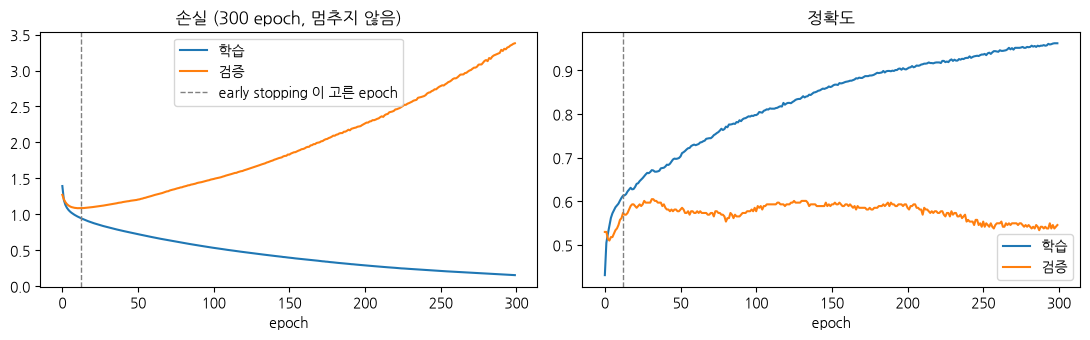

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(long_h.history['loss'], label='학습'); ax[0].plot(long_h.history['val_loss'], label='검증')
ax[0].axvline(best_ep - 1, color='gray', ls='--', lw=1, label='early stopping 이 고른 epoch')
ax[0].set_title('손실 (300 epoch, 멈추지 않음)'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(long_h.history['accuracy'], label='학습'); ax[1].plot(long_h.history['val_accuracy'], label='검증')
ax[1].axvline(best_ep - 1, color='gray', ls='--', lw=1)
ax[1].set_title('정확도'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

## 8. 은닉층 실험
구조를 바꿔 시드 3개(42, 43, 44)로 학습하고 평균을 본다. 모두 같은 early stopping. 구조는 **검증 정확도**로 고르는 것이 원칙이라 검증·테스트를 함께 적는다.

In [12]:
rows = []
for hidden in [(16,), (64,), (64, 32), (128, 64), (256, 128, 64)]:
    va, ta = [], []
    for s in range(3):
        m = build(hidden, seed=SEED + s)
        h = fit(m)
        va.append(h.history['val_accuracy'][int(np.argmin(h.history['val_loss']))])
        ta.append(accuracy_score(y_te, m.predict(X_te, verbose=0).argmax(1)))
    rows.append({'은닉층': str(hidden), '검증 정확도 평균': np.mean(va), '테스트 정확도 평균': np.mean(ta),
                 '테스트 최저': min(ta), '테스트 최고': max(ta)})
EXP = pd.DataFrame(rows).round(3)
EXP

E0000 00:00:1795367091.376937    2580 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795367097.094692    2580 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795367106.529199    2580 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795367111.837668    2580 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1795367116.910584    2580 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1795367124.577904    2580 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


... (2 outputs left out)

E0000 00:00:1795367143.937994    2580 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795367148.992071    2580 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1795367155.443322    2580 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,은닉층,검증 정확도 평균,테스트 정확도 평균,테스트 최저,테스트 최고
0,"(16,)",0.565,0.554,0.545,0.562
1,"(64,)",0.561,0.548,0.533,0.562
2,"(64, 32)",0.568,0.554,0.547,0.562
3,"(128, 64)",0.567,0.557,0.555,0.559
4,"(256, 128, 64)",0.584,0.565,0.555,0.578


## 9. 오답 분석
### 9-1. 혼동행렬 (신경망, 테스트)

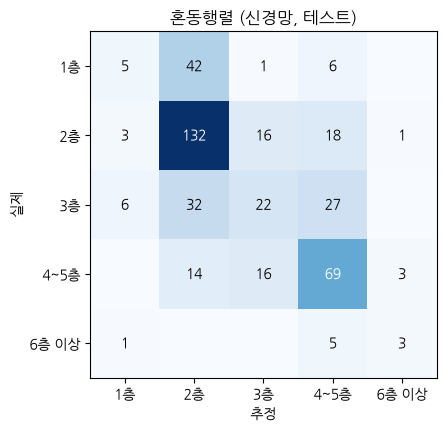

오답 191 동 중 한 구간 차이 144 동 (75%), 두 구간 이상 47 동


In [13]:
cm = confusion_matrix(y_te, p_nn, labels=range(5))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(5)); ax.set_yticks(range(5)); ax.set_xticklabels(LABELS); ax.set_yticklabels(LABELS)
for i in range(5):
    for j in range(5):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xlabel('추정'); ax.set_ylabel('실제'); ax.set_title('혼동행렬 (신경망, 테스트)')
plt.show()
err = np.abs(y_te - p_nn)
print('오답', (err > 0).sum(), '동 중 한 구간 차이', (err == 1).sum(), '동 (%.0f%%), 두 구간 이상' % (100 * (err == 1).sum() / max((err > 0).sum(), 1)), (err >= 2).sum(), '동')

### 9-2. 어떤 건물이 틀리나
바닥면적 크기와 주변 층수가 섞인 정도(이웃 8동 층수 최댓값 − 중앙값)로 나눠 정답률을 본다.

In [14]:
T = te.copy(); T['pred'] = p_nn; T['ok'] = T['pred'] == T['y']
T['면적 구간'] = pd.cut(T['area'], [0, 50, 100, 200, 500, 1e9], labels=['50㎡ 미만', '50~100', '100~200', '200~500', '500㎡ 이상'])
T['주변 섞임'] = np.where(T['nb_flr_max'] - T['nb_flr_med'] >= 3, '섞임 (최댓값−중앙값 ≥ 3층)', '고름')
T['실제 구간'] = pd.Categorical(np.array(LABELS)[T['y']], LABELS)
pd.concat([T.groupby(c, observed=True)['ok'].agg(['size', 'mean']).rename(columns={'size': '동수', 'mean': '정답률'})
           .assign(기준=c).set_index('기준', append=True) for c in ['실제 구간', '면적 구간', '주변 섞임']]).round(3)

,,동수,정답률
,기준,,
1층,실제 구간,54,0.093
2층,실제 구간,170,0.776
3층,실제 구간,87,0.253
4~5층,실제 구간,102,0.676
6층 이상,실제 구간,9,0.333
50㎡ 미만,면적 구간,12,0.250
50~100,면적 구간,92,0.533
100~200,면적 구간,235,0.566
200~500,면적 구간,71,0.563


In [15]:
T['실제'] = np.array(LABELS)[T['y']]; T['추정'] = np.array(LABELS)[T['pred']]
far = T[np.abs(T['y'] - T['pred']) >= 2]
print('두 구간 이상 틀린 건물', len(far), '동 (특징 값만, 이름 없음)')
far[['idx', '실제', '추정', 'area', 'compact', 'nb_flr_med', 'nb_flr_max', 'n_50m']].round(2).head(15)

두 구간 이상 틀린 건물 47 동 (특징 값만, 이름 없음)


,idx,실제,추정,area,compact,nb_flr_med,nb_flr_max,n_50m
1061,1233,4~5층,2층,95.21,0.76,2.5,6.0,21
191,232,1층,4~5층,264.58,0.78,4.0,5.0,18
1530,1779,2층,6층 이상,710.04,0.73,2.0,4.0,12
1287,1510,1층,3층,91.17,0.68,2.5,4.0,21
1144,1342,2층,4~5층,132.97,0.67,3.0,4.0,23
527,622,6층 이상,1층,287.31,0.58,3.0,25.0,8
1374,1607,4~5층,2층,0.08,0.79,3.0,4.0,22
1420,1654,4~5층,2층,196.96,0.56,2.0,4.0,30
1685,1981,2층,4~5층,443.54,0.41,2.0,5.0,10
1476,1718,2층,4~5층,336.90,0.58,2.5,5.0,19


**읽는 법**: 오답의 4분의 3은 바로 옆 구간과 헷갈린 것이다 (2층↔3층, 3층↔4~5층). 1층과 3층은 정답률이 낮다. 바닥 모양과 주변만으로는 1층 건물과 2층 주택, 3층 다가구와 2층·4층 건물을 가르기 어렵다.
주변 층수가 섞인 곳(아파트 단지 가장자리 등)은 정답률이 0.452 로, 고른 곳(0.558)보다 낮다. 바닥면적 크기별로는 50㎡ 미만(12동)을 빼면 큰 차이가 없다.

## 10. 결과표

아래 숫자는 이 노트북을 GitHub Actions(리눅스, 파이썬 3.12, tensorflow-cpu)에서 실행한 결과다 (SEED=42, op determinism). 테스트 422동.

| 방법 | 정확도 | macro F1 | ±1 구간 정확도 |
|---|---|---|---|
| 최빈 구간 (모두 2층) | 0.403 | 0.115 | 0.737 |
| 이웃 8동 다수결 | 0.488 | 0.377 | 0.796 |
| 이웃 8동 중앙값 | 0.469 | 0.348 | 0.827 |
| 로지스틱 회귀 (같은 특징 16개) | 0.540 | 0.419 | 0.879 |
| **신경망 Dense 64-32 (early stopping 13 epoch)** | **0.547** | **0.423** | **0.889** |

| 확인 | 결과 |
|---|---|
| 과적합 | early stopping: 학습 0.614 / 테스트 0.547 (차이 0.067). 멈추지 않고 300 epoch: 학습 0.899 / 테스트 0.495 (차이 0.404) |
| 은닉층 실험 (시드 3개 테스트 평균) | (16) 0.554, (64) 0.548, (64,32) 0.554, (128,64) 0.557, (256,128,64) 0.565. 차이가 시드에 따른 흔들림(약 ±0.01~0.02)과 비슷해 단순한 64-32 를 유지 |
| 오답 | 191동 중 144동(75%)이 한 구간 차이 |
| 추정 대상 | 지상층수가 빈 340동: 1층 168, 2층 112, 3층 26, 4~5층 30, 6층 이상 4. 확률 0.5 미만 139동 |

**정리**: 신경망은 모든 기준선보다 낫지만 로지스틱 회귀와의 차이는 작다(정확도 +0.007). 특징이 16개뿐이고 관계가 단순해서 층을 쌓아도 얻는 것이 적다. 정확히 맞히는 비율은 절반 남짓이고, 한 구간 차이까지 보면 약 89%다. 그래서 화면에서는 **참고용**으로만 쓴다.

In [16]:
pd.DataFrame(RES).T.round(3)

,정확도,macro F1,±1 구간 정확도
최빈 구간(2층),0.403,0.115,0.737
이웃 8동 다수결,0.488,0.377,0.796
이웃 8동 중앙값,0.469,0.348,0.827
로지스틱 회귀,0.540,0.419,0.879
신경망 Dense 64-32,0.547,0.423,0.889


## 11. 화면에 쓰이는 곳
6절의 신경망(학습 데이터로 학습, 위에서 평가한 그 모델)으로 **지상층수가 빈 건물 전부**의 구간을 추정해 `data/building_imputation_pred.csv` 로 저장한다.
`collect/build_web_data.py` 가 이 파일을 읽어 **지상층수가 빈 건물에만** `est_flr`(구간 이름)·`est_p`(확률)를 붙이고, 지도 건물 카드에
"추정 지상층수 | 2층 (신경망 추정, 참고용 · 판정에 쓰지 않음)" 처럼 보여 준다. **판정(대상·경계선·비대상·판정불가)은 실제 건축물대장 값만 쓰므로 바뀌지 않는다.**

**주의**: 빈칸 건물은 건축물대장이 없는 작은 부속 건물·창고 등이 많아 학습 데이터와 성격이 다를 수 있다 (아래 결과에서 1층 추정이 절반). 이런 분포 차이 때문에 테스트 정확도가 빈칸 건물에서도 그대로 나온다고 보장할 수 없다.

같은 모델을 `web/data/models/building_imputation.json` 으로도 내보낸다 (서버 `server/lib/nn.js` 가 TensorFlow 없이 계산, `node server/test/nn.js` 가 아래 예시 5개로 Keras 와 같은지 확인).

In [17]:
M = B[~B['known']].copy()
prob = model.predict(scaler.transform(M[FEATS]).astype('float32'), verbose=0)
M['est_class'] = prob.argmax(1)
M['est_flr'] = np.array(LABELS)[M['est_class']]
M['est_p'] = prob.max(1).round(3)
out = M[['idx', 'pnu', 'est_class', 'est_flr', 'est_p']]
OUT_DIR = '../data' if os.path.isdir('../data') else '.'
out.to_csv(os.path.join(OUT_DIR, 'building_imputation_pred.csv'), index=False, encoding='utf-8-sig')
print('추정한 건물', len(out), '동 →', os.path.join(OUT_DIR, 'building_imputation_pred.csv'))
print('확률 0.5 미만', (out['est_p'] < 0.5).sum(), '동')
out['est_flr'].value_counts().reindex(LABELS, fill_value=0).to_frame('동수').T

추정한 건물 340 동 → ../data/building_imputation_pred.csv
확률 0.5 미만 139 동


est_flr,1층,2층,3층,4~5층,6층 이상
동수,168,112,26,30,4


In [18]:
def b64(a):
    return base64.b64encode(np.asarray(a, dtype='<f4').tobytes()).decode('ascii')

layers = []
for L in model.layers:
    W, b = L.get_weights()
    layers.append({'units': int(W.shape[1]), 'activation': L.get_config()['activation'], 'W': b64(W), 'b': [float(x) for x in b]})
ex = M.head(5)
check = [{'input': {k: float(r[k]) for k in FEATS}, 'output': [float(x) for x in p]}
         for (_, r), p in zip(ex.iterrows(), model.predict(scaler.transform(ex[FEATS]).astype('float32'), verbose=0))]
spec = {
    'name': 'building_imputation',
    'note': '지상층수 구간 추정 (참고용, 판정에 쓰지 않음). 특징은 notebooks/building_imputation.ipynb 3절',
    'input': {'type': 'dense', 'features': FEATS, 'mean': [float(x) for x in scaler.mean_], 'scale': [float(x) for x in scaler.scale_]},
    'layers': layers,
    'labels': LABELS,
    'metrics': {k: {m: round(float(v), 3) for m, v in s.items()} for k, s in RES.items()},
    'check': check,
}
MODEL_DIR = '../web/data/models' if os.path.isdir('../web/data') else '.'
os.makedirs(MODEL_DIR, exist_ok=True)
with open(os.path.join(MODEL_DIR, 'building_imputation.json'), 'w', encoding='utf-8') as f:
    json.dump(spec, f, ensure_ascii=False)
print('모델 저장', os.path.join(MODEL_DIR, 'building_imputation.json'))

모델 저장 ../web/data/models/building_imputation.json
